# Part 7 Business Recommendations and Decision Support



After completing the sales analysis, I wanted to bring the main findings together and understand how they could help Melt Gelato make better business decisions.

In this final part, I reviewed the forecasting results, product performance, category demand patterns and market basket findings.

The aim was to turn these results into practical recommendations for inventory planning, staffing and daily operations.

## 7.1 Load validated analysis outputs

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
HERE=Path.cwd()
ROOT=HERE.parent if HERE.name=='notebooks' else HERE
P=ROOT/'data'/'processed'
names={'forecast':'forecast_model_comparison.csv','abc':'product_abc_summary.csv','items':'product_abc_classification.csv','variation':'category_demand_variability.csv','pairs':'product_basket_rules.csv'}
for name in names.values():
    assert (P/name).exists(), f'Missing {P/name}; run Part 5 or 6 first.'
datasets={key:pd.read_csv(P/filename) for key,filename in names.items()}
for key,frame in datasets.items():print(key,frame.shape)

forecast (3, 4)
abc (3, 5)
items (387, 10)
variation (10, 5)
pairs (960, 6)


### Choosing a Forecasting Model

I compared the forecasting models to identify which one predicted daily revenue most accurately.

Calendar Ridge achieved the lowest test error, with an MAE of €153.61 and WAPE of 12.74%.

This suggests that calendar-based forecasting could be a useful starting point for planning daily operations. However, the model would need further testing before being used regularly by the business.


## 7.2 Forecast model selection

,model,MAE_eur,RMSE_eur,WAPE_pct
0,Calendar Ridge,153.61,204.62,12.74
1,Calendar + observed weather Ridge,181.29,226.92,15.03
2,Seasonal naive (t-7),227.08,300.88,18.83


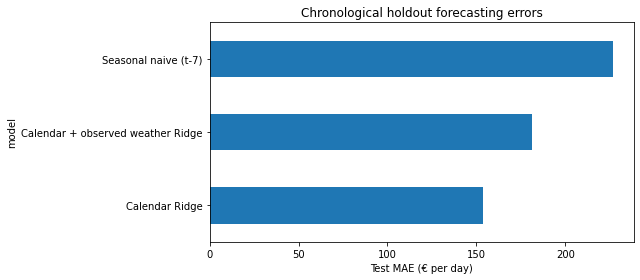

Lowest holdout MAE: Calendar Ridge


In [2]:
f=datasets['forecast'].sort_values('MAE_eur')
display(f.round(2))
ax=f.plot.barh(x='model',y='MAE_eur',legend=False,figsize=(9,4))
ax.set_xlabel('Test MAE (€ per day)');ax.set_title('Chronological holdout forecasting errors');plt.tight_layout();plt.show()
print('Lowest holdout MAE:',f.iloc[0]['model'])

### Identifying Priority Products

Next, I reviewed the ABC classification results to identify the products contributing most to Melt Gelato's revenue.

The analysis showed that 44 out of 387 products generated 80.45% of payment revenue.

This highlights the importance of keeping high-revenue products available, particularly during busy periods.

However, revenue alone does not indicate profitability, so product costs and stock availability should also be considered.

## 7.3 Revenue priorities and product concentration

,abc_class,products,payment_revenue_eur,revenue_share_pct,product_share_pct
0,A,44,441076.70,80.45,11.37
1,B,61,79933.70,14.58,15.76
2,C,282,27233.95,4.97,72.87


,item_clean,payment_gross_eur
0,Gelato,120501.8
1,Vanilla Milkshake,41544.0
2,Cappuccino,31327.2
3,Melted tub,17894.5
4,Bueno Buster Tub,15446.0
5,99 Cones,14944.6
6,Americano,13235.7
7,Strawberry & Nutella crepe,12675.0
8,Nutella Crepe,11377.5
9,White Kinder Tub,10142.0


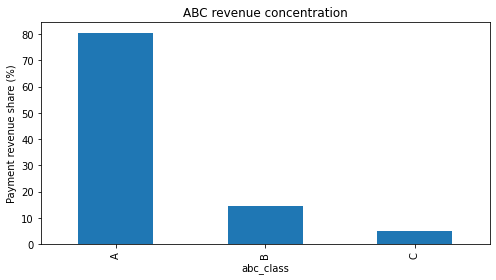

In [3]:
abc=datasets['abc'];items=datasets['items']
display(abc.sort_values('abc_class').round(2))
display(items.loc[items['abc_class']=='A'].sort_values('payment_gross_eur',ascending=False)[['item_clean','payment_gross_eur']].head(12).round(2))
ax=abc.plot.bar(x='abc_class',y='revenue_share_pct',legend=False,figsize=(7,4))
ax.set_ylabel('Payment revenue share (%)');ax.set_title('ABC revenue concentration');plt.tight_layout();plt.show()

### Understanding Product Demand and Purchase Patterns

I also compared how daily revenue varied across product categories.

Gelato showed greater demand variability (CV = 0.69) than Coffee (CV = 0.25), suggesting that gelato preparation may need to be more flexible.

The market basket analysis also identified products frequently purchased together. For example, Gelato and Topping appeared together in 5,905 transactions.

These findings could help with product preparation and potential promotional ideas, although the combinations should be checked against the existing menu before introducing offers.

## 7.4 Category volatility and basket candidates

In [4]:
v=datasets['variation']
if 'category_clean' not in v.columns:v=v.rename(columns={v.columns[0]:'category_clean'})
display(v.sort_values('mean_daily_revenue_eur',ascending=False)[['category_clean','mean_daily_revenue_eur','cv']].head(10).round(2))
pairs=datasets['pairs']
if pairs.empty:print('No basket associations met the thresholds.')
else:display(pairs.sort_values(['baskets_together','lift'],ascending=False).head(12).round(3))

,category_clean,mean_daily_revenue_eur,cv
1,Gelato,400.07,0.69
0,Coffee,273.07,0.25
6,Special Tubs,247.97,0.67
9,Waffles and Crepes,205.35,0.43
4,Milkshakes,127.92,0.55
3,Menu,44.96,0.66
8,Uncategorised,44.79,1.40
2,Grilled Sandwiches,33.96,0.70
7,Toppings,30.03,0.78
5,Pastries,26.30,0.94


,antecedent,consequent,baskets_together,support_pct,confidence_pct,lift
202,Gelato,Topping,5905,10.027,35.315,2.506
203,Topping,Gelato,5905,10.027,71.145,2.506
218,Topping,99 Cones,1386,2.354,16.699,2.402
219,99 Cones,Topping,1386,2.354,33.854,2.402
512,Gelato,99 Cones,1267,2.151,7.577,1.090
513,99 Cones,Gelato,1267,2.151,30.948,1.090
222,Gelato,Hot sauce,1094,1.858,6.543,2.377
223,Hot sauce,Gelato,1094,1.858,67.489,2.377
788,Gelato,Vanilla Milkshake,1075,1.825,6.429,0.671
789,Vanilla Milkshake,Gelato,1075,1.825,19.043,0.671


### Turning Findings into Recommendations

Based on the analysis, I prepared a decision register that connects the main findings with possible actions for Melt Gelato.

I assigned priorities to the recommendations and identified what the business would need to check before implementing them.

The focus was on suggesting realistic improvements rather than assuming that every finding would immediately lead to better results.

## 7.5 Evidence-to-action register

In [5]:
actions=pd.DataFrame([
{'priority':'High','finding':'Calendar Ridge had lowest test MAE','proposed_action':'Pilot calendar-based revenue planning','verify_before_action':'Rolling-origin validation and forecast error by season'},
{'priority':'High','finding':'A-class products drive most payment revenue','proposed_action':'Review availability of leading A-class products','verify_before_action':'Margins, stockouts, lead times, item definitions'},
{'priority':'Medium','finding':'Gelato revenue is more variable than Coffee','proposed_action':'Review flexible daily preparation practices','verify_before_action':'Ingredient use, spoilage and production logs'},
{'priority':'Medium','finding':'Certain product pairs recur in baskets','proposed_action':'Consider small menu placement or bundle experiment','verify_before_action':'Check modifiers; evaluate incremental lift'},
{'priority':'Research','finding':'Observed weather worsened forecast test MAE','proposed_action':'Do not deploy observed-weather model yet','verify_before_action':'Actual weather forecast inputs and rolling tests'}])
display(actions)
actions.to_csv(P/'business_decision_register.csv',index=False)
print('Saved business_decision_register.csv')

,priority,finding,proposed_action,verify_before_action
0,High,Calendar Ridge had lowest test MAE,Pilot calendar-based revenue planning,Rolling-origin validation and forecast error b...
1,High,A-class products drive most payment revenue,Review availability of leading A-class products,"Margins, stockouts, lead times, item definitions"
2,Medium,Gelato revenue is more variable than Coffee,Review flexible daily preparation practices,"Ingredient use, spoilage and production logs"
3,Medium,Certain product pairs recur in baskets,Consider small menu placement or bundle experi...,Check modifiers; evaluate incremental lift
4,Research,Observed weather worsened forecast test MAE,Do not deploy observed-weather model yet,Actual weather forecast inputs and rolling tests


Saved business_decision_register.csv


## 7.6 Final interpretation and limitations


The analysis identified opportunities to improve Melt Gelato’s operational planning and product management.

Sales Forecasting: Calendar Ridge achieved the best forecasting performance, with an MAE of €153.61 and WAPE of 12.74%. Although weather significantly influenced historical sales patterns, including weather variables did not improve forecasting accuracy. Therefore, calendar-based forecasting is the preferred approach for further testing.

ABC Analysis: Only 44 out of 387 products generated 80.45% of payment revenue, highlighting the importance of prioritising high-revenue products for availability and stock planning.

Demand Variability: Gelato showed considerably greater daily revenue variability (CV = 0.69) than Coffee (CV = 0.25), suggesting that flexible preparation and staffing strategies may be beneficial.

Market Basket Analysis: Gelato and Topping appeared together in 5,905 transactions (lift = 2.506), indicating a strong purchasing association. However, this relationship should be validated against the menu structure before introducing promotional bundles.

Overall Finding: Melt Gelato could benefit from calendar-based demand forecasting, revenue-driven product prioritisation, and more flexible operational planning. These recommendations should be tested using additional operational data before implementation.